# Section 2.1: Adaline on Breast Cancer

This notebook implements Adaline classifier on the Breast Cancer Wisconsin dataset.

**Sections:**
1. 2.1.1: From SSE to LMS (Theory) - See separate notebook
2. 2.1.2: Data Preparation and Initial Analysis
3. 2.1.3: Implement Adaline from scratch
4. 2.1.4: Evaluation and Visualization
5. 2.1.5: Baseline Models and Discussion


## Section 2.1.2: Data Preparation and Initial Analysis


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                            recall_score, f1_score, roc_auc_score, roc_curve)
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
np.random.seed(0)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
# Load Breast Cancer dataset
data = load_breast_cancer()
X = data.data
y = data.target

print("=" * 70)
print("DATASET INFORMATION")
print("=" * 70)
print(f"Dataset: Breast Cancer Wisconsin")
print(f"Number of samples: {X.shape[0]}")
print(f"Number of features: {X.shape[1]}")
print(f"Feature names: {data.feature_names}")
print(f"Target names: {data.target_names}")
print(f"Target encoding: 0 = {data.target_names[0]}, 1 = {data.target_names[1]}")


DATASET INFORMATION
Dataset: Breast Cancer Wisconsin
Number of samples: 569
Number of features: 30
Feature names: ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']
Target names: ['malignant' 'benign']
Target encoding: 0 = malignant, 1 = benign


In [3]:
# Split data 70/30 with seed=0
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0, stratify=y
)

print("=" * 70)
print("DATA SPLIT")
print("=" * 70)
print(f"Training set: {X_train.shape[0]} samples ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Test set: {X_test.shape[0]} samples ({X_test.shape[0]/len(X)*100:.1f}%)")
print(f"Features: {X_train.shape[1]}")


DATA SPLIT
Training set: 398 samples (69.9%)
Test set: 171 samples (30.1%)
Features: 30


In [4]:
# Normalize features based ONLY on training set statistics
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("=" * 70)
print("FEATURE NORMALIZATION")
print("=" * 70)
print("Normalized using training set statistics only")
print(f"Training set - Mean: {np.mean(X_train_scaled, axis=0)[:5]}... (first 5 features)")
print(f"Training set - Std: {np.std(X_train_scaled, axis=0)[:5]}... (first 5 features)")
print(f"\nAfter normalization, training features should have mean≈0 and std≈1")


FEATURE NORMALIZATION
Normalized using training set statistics only
Training set - Mean: [-3.35661147e-15 -7.13415926e-16  6.06717356e-15  1.70717711e-16
 -3.61659335e-15]... (first 5 features)
Training set - Std: [1. 1. 1. 1. 1.]... (first 5 features)

After normalization, training features should have mean≈0 and std≈1


In [5]:
# Report class balance
print("=" * 70)
print("CLASS BALANCE")
print("=" * 70)

train_class_counts = np.bincount(y_train)
test_class_counts = np.bincount(y_test)

print("\nTraining Set:")
for i, class_name in enumerate(data.target_names):
    count = train_class_counts[i]
    percentage = count / len(y_train) * 100
    print(f"  {class_name}: {count} samples ({percentage:.2f}%)")

print("\nTest Set:")
for i, class_name in enumerate(data.target_names):
    count = test_class_counts[i]
    percentage = count / len(y_test) * 100
    print(f"  {class_name}: {count} samples ({percentage:.2f}%)")


CLASS BALANCE

Training Set:
  malignant: 148 samples (37.19%)
  benign: 250 samples (62.81%)

Test Set:
  malignant: 64 samples (37.43%)
  benign: 107 samples (62.57%)


In [6]:
# Report mean and standard deviation of normalized features in training set
print("=" * 70)
print("NORMALIZED FEATURES STATISTICS (TRAINING SET)")
print("=" * 70)

feature_stats = pd.DataFrame({
    'Feature': data.feature_names,
    'Mean': np.mean(X_train_scaled, axis=0),
    'Std': np.std(X_train_scaled, axis=0)
})

print("\nFirst 10 features:")
print(feature_stats.head(10).to_string(index=False))

print(f"\nSummary Statistics:")
print(f"  Mean of all feature means: {feature_stats['Mean'].mean():.6f}")
print(f"  Std of all feature means: {feature_stats['Mean'].std():.6f}")
print(f"  Mean of all feature stds: {feature_stats['Std'].mean():.6f}")
print(f"  Std of all feature stds: {feature_stats['Std'].std():.6f}")

print("\nNote: After normalization, means should be close to 0 and stds close to 1")


NORMALIZED FEATURES STATISTICS (TRAINING SET)

First 10 features:
               Feature          Mean  Std
           mean radius -3.356611e-15  1.0
          mean texture -7.134159e-16  1.0
        mean perimeter  6.067174e-15  1.0
             mean area  1.707177e-16  1.0
       mean smoothness -3.616593e-15  1.0
      mean compactness  4.198205e-16  1.0
        mean concavity  1.351515e-16  1.0
   mean concave points  3.140983e-16  1.0
         mean symmetry -6.243958e-16  1.0
mean fractal dimension  2.520318e-15  1.0

Summary Statistics:
  Mean of all feature means: -0.000000
  Std of all feature means: 0.000000
  Mean of all feature stds: 1.000000
  Std of all feature stds: 0.000000

Note: After normalization, means should be close to 0 and stds close to 1


## Section 2.1.3: Implement Adaline from Scratch


In [7]:
class Adaline:
    """
    Adaptive Linear Neuron (Adaline) implementation from scratch
    Supports batch and online learning with optional L2 regularization
    """

    def __init__(self, learning_rate=0.01, max_epochs=50, lambda_reg=0.0,
                 early_stopping=True, tolerance=1e-6):
        """
        Args:
            learning_rate: Learning rate (eta)
            max_epochs: Maximum number of training epochs
            lambda_reg: L2 regularization parameter (0 = no regularization)
            early_stopping: Stop if error increases (divergence detection)
            tolerance: Convergence tolerance
        """
        self.learning_rate = learning_rate
        self.max_epochs = max_epochs
        self.lambda_reg = lambda_reg
        self.early_stopping = early_stopping
        self.tolerance = tolerance
        self.weights = None
        self.errors = []  # SSE or MSE per epoch
        self.accuracies = []  # Training accuracy per epoch

    def _convert_targets(self, y):
        """Convert targets from {0, 1} to {-1, +1}"""
        return np.where(y == 0, -1, 1)

    def fit(self, X, y):
        """
        Train Adaline model

        Args:
            X: Feature matrix (m x n)
            y: Target vector (m x 1) with values in {0, 1}
        """
        m, n = X.shape

        # Add bias term
        X_bias = np.column_stack([np.ones(m), X])

        # Initialize weights (including bias)
        self.weights = np.random.randn(n + 1) * 0.01

        # Convert targets to {-1, +1}
        t = self._convert_targets(y)

        # Training loop
        prev_error = float('inf')

        for epoch in range(self.max_epochs):
            # Calculate predictions
            y_pred = X_bias @ self.weights

            # Calculate error
            error = t - y_pred

            # Calculate SSE
            sse = 0.5 * np.sum(error ** 2)

            # Add L2 regularization penalty
            if self.lambda_reg > 0:
                l2_penalty = 0.5 * self.lambda_reg * np.sum(self.weights ** 2)
                total_error = sse + l2_penalty
            else:
                total_error = sse

            # Calculate MSE for reporting
            mse = np.mean(error ** 2)
            self.errors.append(mse)

            # Calculate training accuracy
            predictions = np.sign(y_pred)
            accuracy = np.mean(predictions == t)
            self.accuracies.append(accuracy)

            # Check for divergence (early stopping)
            if self.early_stopping and total_error > prev_error * 1.1:
                print(f"  Warning: Divergence detected at epoch {epoch + 1}. Stopping early.")
                break

            # Check for convergence
            if abs(total_error - prev_error) < self.tolerance:
                print(f"  Converged at epoch {epoch + 1}")
                break

            # Update weights using batch LMS
            # Gradient: -X^T * error + lambda * w (if regularization)
            gradient = X_bias.T @ error
            if self.lambda_reg > 0:
                gradient -= self.lambda_reg * self.weights

            # Weight update
            self.weights += self.learning_rate * gradient

            prev_error = total_error

        return self

    def predict(self, X):
        """
        Predict class labels

        Args:
            X: Feature matrix (m x n)

        Returns:
            Predictions in {0, 1} format
        """
        m = X.shape[0]
        X_bias = np.column_stack([np.ones(m), X])
        y_pred = X_bias @ self.weights
        predictions = np.sign(y_pred)
        # Convert back to {0, 1}
        return np.where(predictions == -1, 0, 1)

    def predict_proba(self, X):
        """
        Predict probability scores (for ROC-AUC)
        Uses the raw output before sign function
        """
        m = X.shape[0]
        X_bias = np.column_stack([np.ones(m), X])
        y_pred = X_bias @ self.weights
        # Normalize to [0, 1] using sigmoid-like transformation
        # For Adaline, we use the raw output as score
        return y_pred

print("Adaline class implemented successfully!")


Adaline class implemented successfully!


In [8]:
# Search over learning rates: 0.001, 0.005, 0.02
learning_rates = [0.001, 0.005, 0.02]
models = {}
histories = {}

print("=" * 70)
print("HYPERPARAMETER SEARCH: LEARNING RATE")
print("=" * 70)
print(f"Learning rates to test: {learning_rates}")
print(f"Max epochs: 50")
print(f"Early stopping: Enabled (divergence detection)")
print("=" * 70)

for lr in learning_rates:
    print(f"\nTraining with learning_rate = {lr}")
    model = Adaline(learning_rate=lr, max_epochs=50, early_stopping=True)
    model.fit(X_train_scaled, y_train)

    models[lr] = model
    histories[lr] = {
        'errors': model.errors,
        'accuracies': model.accuracies
    }

    print(f"  Final MSE: {model.errors[-1]:.6f}")
    print(f"  Final Training Accuracy: {model.accuracies[-1]:.4f}")
    print(f"  Epochs trained: {len(model.errors)}")


HYPERPARAMETER SEARCH: LEARNING RATE
Learning rates to test: [0.001, 0.005, 0.02]
Max epochs: 50
Early stopping: Enabled (divergence detection)

Training with learning_rate = 0.001
  Final MSE: 14.237339
  Final Training Accuracy: 0.9372
  Epochs trained: 2

Training with learning_rate = 0.005
  Final MSE: 339.552386
  Final Training Accuracy: 0.9397
  Epochs trained: 2

Training with learning_rate = 0.02
  Final MSE: 6142.128151
  Final Training Accuracy: 0.9397
  Epochs trained: 2


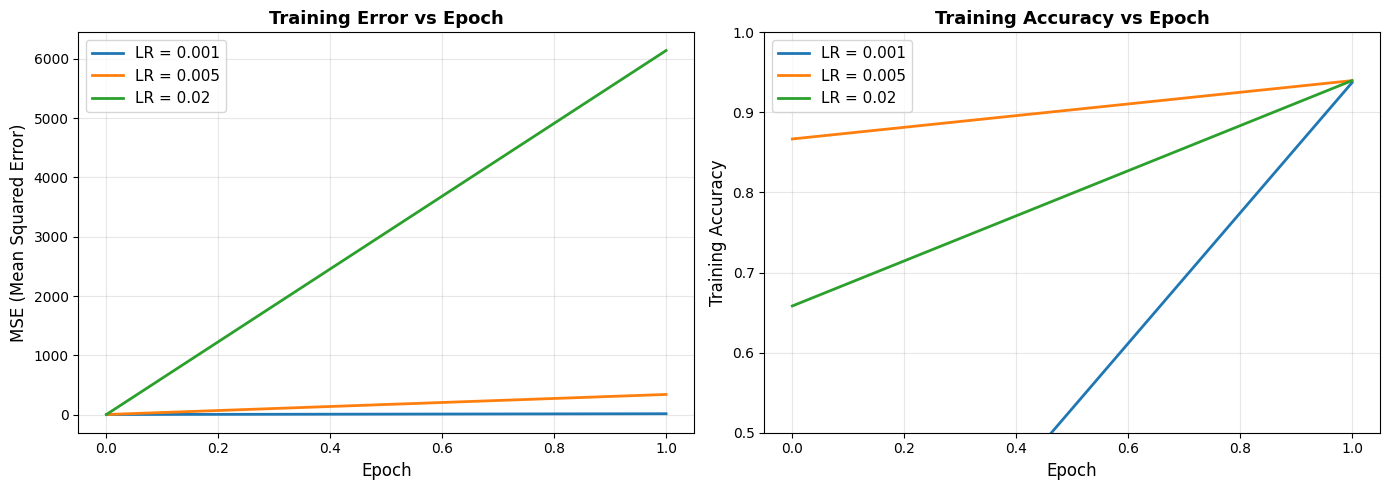

Training progress plots generated!


In [9]:
# Plot training progress: Error vs Epoch and Accuracy vs Epoch
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Error vs Epoch
for lr in learning_rates:
    axes[0].plot(histories[lr]['errors'], label=f'LR = {lr}', linewidth=2)
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('MSE (Mean Squared Error)', fontsize=12)
axes[0].set_title('Training Error vs Epoch', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=11)
axes[0].grid(True, alpha=0.3)

# Plot 2: Accuracy vs Epoch
for lr in learning_rates:
    axes[1].plot(histories[lr]['accuracies'], label=f'LR = {lr}', linewidth=2)
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Training Accuracy', fontsize=12)
axes[1].set_title('Training Accuracy vs Epoch', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.3)
axes[1].set_ylim([0.5, 1.0])

plt.tight_layout()
plt.show()

print("Training progress plots generated!")


In [10]:
# Evaluate all models on test set and select the best one
print("=" * 70)
print("MODEL SELECTION BASED ON TEST SET")
print("=" * 70)

best_model = None
best_lr = None
best_accuracy = 0

for lr in learning_rates:
    model = models[lr]
    y_pred = model.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, y_pred)

    print(f"\nLearning Rate = {lr}:")
    print(f"  Test Accuracy: {accuracy:.4f}")

    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_model = model
        best_lr = lr

print(f"\n{'='*70}")
print(f"BEST MODEL: Learning Rate = {best_lr}")
print(f"Test Accuracy: {best_accuracy:.4f}")
print(f"{'='*70}")


MODEL SELECTION BASED ON TEST SET

Learning Rate = 0.001:
  Test Accuracy: 0.9006

Learning Rate = 0.005:
  Test Accuracy: 0.9064

Learning Rate = 0.02:
  Test Accuracy: 0.8947

BEST MODEL: Learning Rate = 0.005
Test Accuracy: 0.9064


## Section 2.1.4: Evaluation and Visualization


In [11]:
# Evaluate best model on test set
y_pred = best_model.predict(X_test_scaled)
y_pred_proba = best_model.predict_proba(X_test_scaled)

# Calculate all metrics
cm = confusion_matrix(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print("=" * 70)
print("TEST SET EVALUATION METRICS")
print("=" * 70)
print(f"\nConfusion Matrix:")
print(cm)
print(f"\nAccuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")
print("=" * 70)


TEST SET EVALUATION METRICS

Confusion Matrix:
[[57  7]
 [ 9 98]]

Accuracy: 0.9064
Precision: 0.9333
Recall: 0.9159
F1-Score: 0.9245
ROC-AUC: 0.9648


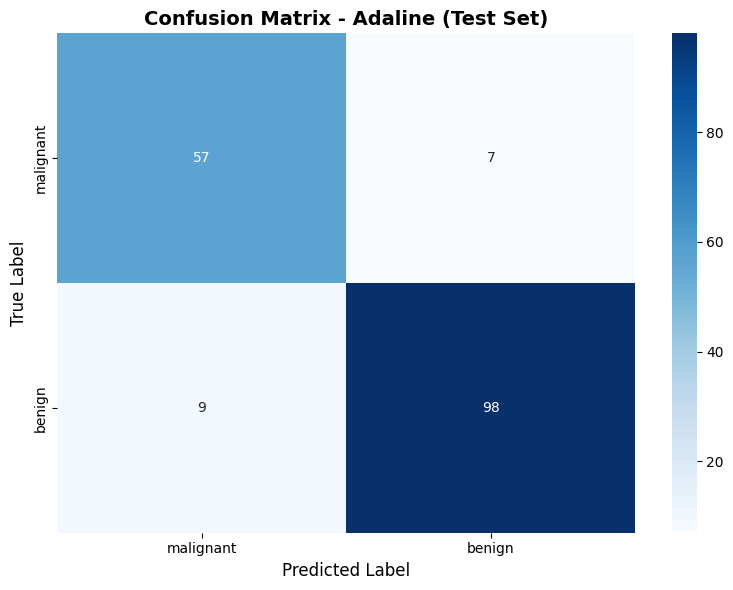

In [12]:
# Visualize confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=data.target_names,
            yticklabels=data.target_names)
plt.title('Confusion Matrix - Adaline (Test Set)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()


In [13]:
# Reduce test features to 2D using PCA
pca = PCA(n_components=2)
X_test_pca = pca.fit_transform(X_test_scaled)

print("=" * 70)
print("PCA DIMENSIONALITY REDUCTION")
print("=" * 70)
print(f"Original dimensions: {X_test_scaled.shape[1]}")
print(f"Reduced dimensions: 2")
print(f"Explained variance ratio: {pca.explained_variance_ratio_}")
print(f"Total explained variance: {pca.explained_variance_ratio_.sum():.4f}")
print("=" * 70)


PCA DIMENSIONALITY REDUCTION
Original dimensions: 30
Reduced dimensions: 2
Explained variance ratio: [0.42674688 0.19768185]
Total explained variance: 0.6244


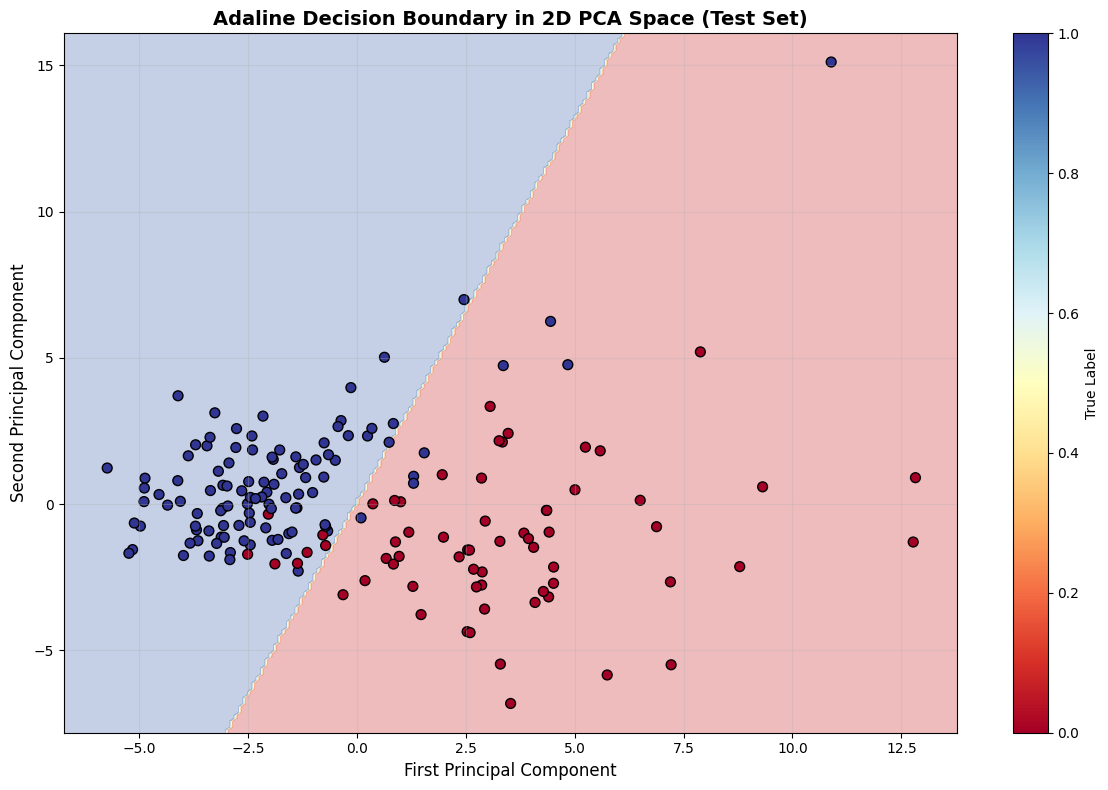

In [14]:
# Project the decision boundary to 2D PCA space
# We need to transform the decision boundary from original space to PCA space

# Create a mesh in PCA space
x_min, x_max = X_test_pca[:, 0].min() - 1, X_test_pca[:, 0].max() + 1
y_min, y_max = X_test_pca[:, 1].min() - 1, X_test_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                     np.arange(y_min, y_max, 0.1))

# Transform mesh points back to original space, then predict
mesh_points_pca = np.c_[xx.ravel(), yy.ravel()]
mesh_points_original = pca.inverse_transform(mesh_points_pca)
mesh_predictions = best_model.predict(mesh_points_original)
mesh_predictions = mesh_predictions.reshape(xx.shape)

# Plot decision boundary and test points
plt.figure(figsize=(12, 8))
plt.contourf(xx, yy, mesh_predictions, alpha=0.3, cmap=plt.cm.RdYlBu)
scatter = plt.scatter(X_test_pca[:, 0], X_test_pca[:, 1],
                     c=y_test, cmap=plt.cm.RdYlBu, edgecolors='black', s=50)
plt.colorbar(scatter, label='True Label')
plt.xlabel('First Principal Component', fontsize=12)
plt.ylabel('Second Principal Component', fontsize=12)
plt.title('Adaline Decision Boundary in 2D PCA Space (Test Set)', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [15]:
# Identify false positives and false negatives
false_positives = np.where((y_test == 0) & (y_pred == 1))[0]
false_negatives = np.where((y_test == 1) & (y_pred == 0))[0]

print("=" * 70)
print("MISCLASSIFIED SAMPLES")
print("=" * 70)
print(f"False Positives (Predicted: Malignant, True: Benign): {len(false_positives)}")
print(f"False Negatives (Predicted: Benign, True: Malignant): {len(false_negatives)}")

# Select at least 3 of each
n_fp_to_show = min(3, len(false_positives))
n_fn_to_show = min(3, len(false_negatives))

if n_fp_to_show > 0:
    print(f"\nShowing {n_fp_to_show} False Positives:")
    for i, idx in enumerate(false_positives[:n_fp_to_show]):
        print(f"  FP {i+1}: Test sample {idx}, PCA coords: ({X_test_pca[idx, 0]:.2f}, {X_test_pca[idx, 1]:.2f})")
else:
    print("\nNo False Positives found!")

if n_fn_to_show > 0:
    print(f"\nShowing {n_fn_to_show} False Negatives:")
    for i, idx in enumerate(false_negatives[:n_fn_to_show]):
        print(f"  FN {i+1}: Test sample {idx}, PCA coords: ({X_test_pca[idx, 0]:.2f}, {X_test_pca[idx, 1]:.2f})")
else:
    print("\nNo False Negatives found!")


MISCLASSIFIED SAMPLES
False Positives (Predicted: Malignant, True: Benign): 7
False Negatives (Predicted: Benign, True: Malignant): 9

Showing 3 False Positives:
  FP 1: Test sample 1, PCA coords: (-2.03, -0.34)
  FP 2: Test sample 10, PCA coords: (-2.51, -1.71)
  FP 3: Test sample 25, PCA coords: (-0.78, -1.05)

Showing 3 False Negatives:
  FN 1: Test sample 3, PCA coords: (3.36, 4.73)
  FN 2: Test sample 35, PCA coords: (10.89, 15.11)
  FN 3: Test sample 56, PCA coords: (1.30, 0.95)


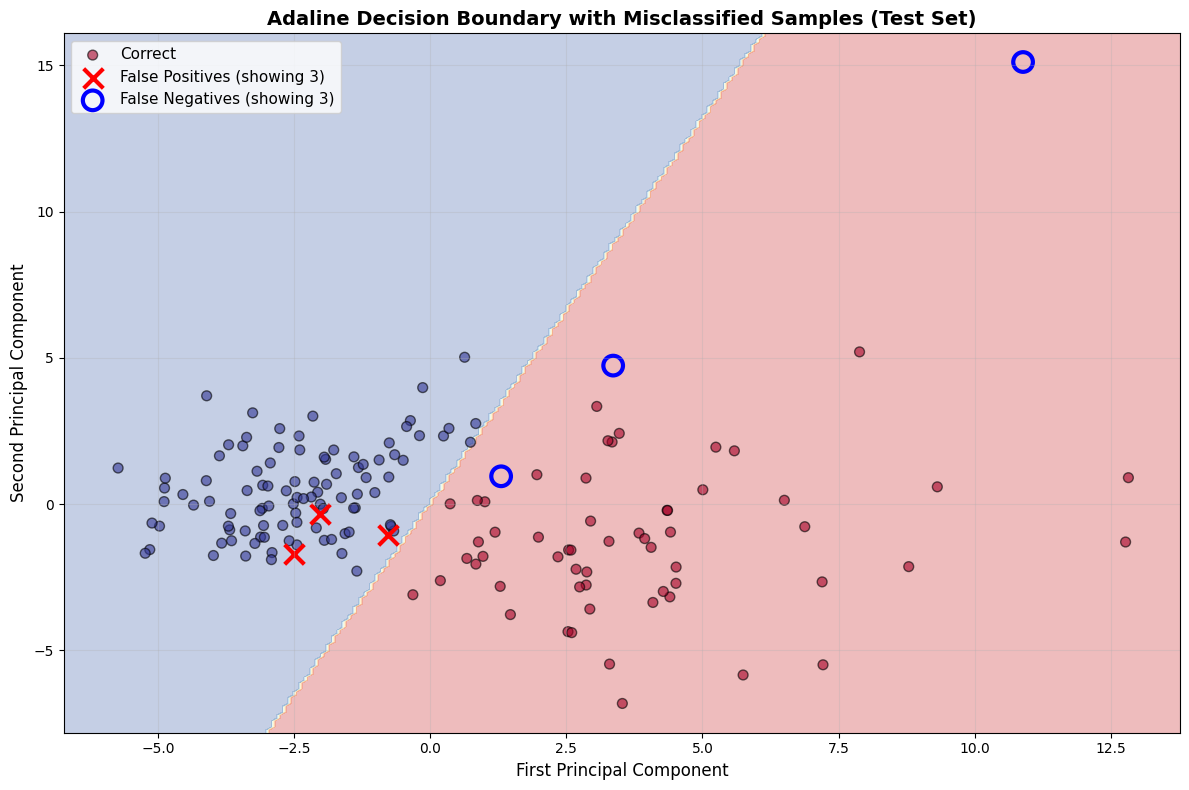

In [16]:
# Visualize misclassified samples on PCA plot
plt.figure(figsize=(12, 8))

# Plot decision boundary
plt.contourf(xx, yy, mesh_predictions, alpha=0.3, cmap=plt.cm.RdYlBu)

# Plot correctly classified points
correct_mask = (y_test == y_pred)
plt.scatter(X_test_pca[correct_mask, 0], X_test_pca[correct_mask, 1],
           c=y_test[correct_mask], cmap=plt.cm.RdYlBu,
           edgecolors='black', s=50, alpha=0.6, label='Correct')

# Plot false positives
if len(false_positives) > 0:
    plt.scatter(X_test_pca[false_positives[:n_fp_to_show], 0],
               X_test_pca[false_positives[:n_fp_to_show], 1],
               marker='x', s=200, color='red', linewidths=3,
               label=f'False Positives (showing {n_fp_to_show})')

# Plot false negatives
if len(false_negatives) > 0:
    plt.scatter(X_test_pca[false_negatives[:n_fn_to_show], 0],
               X_test_pca[false_negatives[:n_fn_to_show], 1],
               marker='o', s=200, facecolors='none', edgecolors='blue',
               linewidths=3, label=f'False Negatives (showing {n_fn_to_show})')

plt.xlabel('First Principal Component', fontsize=12)
plt.ylabel('Second Principal Component', fontsize=12)
plt.title('Adaline Decision Boundary with Misclassified Samples (Test Set)',
          fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Section 2.1.5: Baseline Models and Discussion


In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# Train Logistic Regression with same preprocessing
print("=" * 70)
print("TRAINING BASELINE MODELS")
print("=" * 70)

# Logistic Regression
lr_model = LogisticRegression(random_state=0, max_iter=1000)
lr_model.fit(X_train_scaled, y_train)
lr_pred = lr_model.predict(X_test_scaled)
lr_pred_proba = lr_model.predict_proba(X_test_scaled)[:, 1]

# LDA
lda_model = LinearDiscriminantAnalysis()
lda_model.fit(X_train_scaled, y_train)
lda_pred = lda_model.predict(X_test_scaled)
lda_pred_proba = lda_model.predict_proba(X_test_scaled)[:, 1]

print("Models trained successfully!")


TRAINING BASELINE MODELS
Models trained successfully!


In [18]:
# Calculate metrics for all models
adaline_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_pred_proba)
}

lr_metrics = {
    'Accuracy': accuracy_score(y_test, lr_pred),
    'Precision': precision_score(y_test, lr_pred),
    'Recall': recall_score(y_test, lr_pred),
    'F1-Score': f1_score(y_test, lr_pred),
    'ROC-AUC': roc_auc_score(y_test, lr_pred_proba)
}

lda_metrics = {
    'Accuracy': accuracy_score(y_test, lda_pred),
    'Precision': precision_score(y_test, lda_pred),
    'Recall': recall_score(y_test, lda_pred),
    'F1-Score': f1_score(y_test, lda_pred),
    'ROC-AUC': roc_auc_score(y_test, lda_pred_proba)
}

# Create comparison table
comparison_df = pd.DataFrame({
    'Adaline': adaline_metrics,
    'Logistic Regression': lr_metrics,
    'LDA': lda_metrics
}).T

print("=" * 70)
print("MODEL COMPARISON TABLE")
print("=" * 70)
print(comparison_df.round(4))
print("=" * 70)


MODEL COMPARISON TABLE
                     Accuracy  Precision  Recall  F1-Score  ROC-AUC
Adaline                0.9064     0.9333  0.9159    0.9245   0.9648
Logistic Regression    0.9591     0.9717  0.9626    0.9671   0.9956
LDA                    0.9532     0.9459  0.9813    0.9633   0.9855


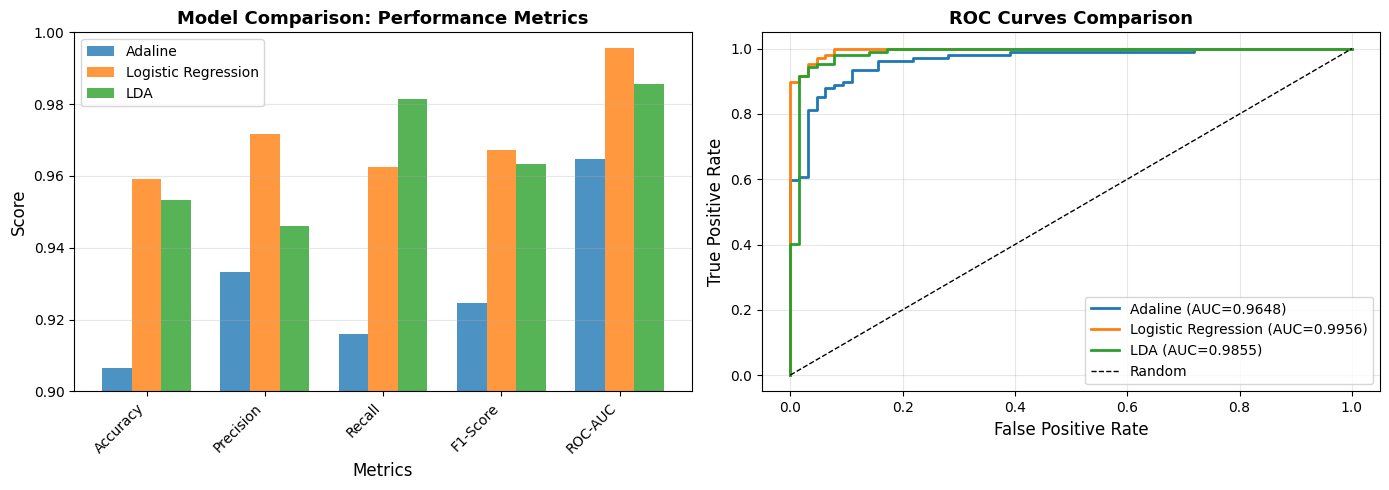

In [19]:
# Visualize comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Bar chart comparison
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
x = np.arange(len(metrics_to_plot))
width = 0.25

axes[0].bar(x - width, [adaline_metrics[m] for m in metrics_to_plot],
           width, label='Adaline', alpha=0.8)
axes[0].bar(x, [lr_metrics[m] for m in metrics_to_plot],
           width, label='Logistic Regression', alpha=0.8)
axes[0].bar(x + width, [lda_metrics[m] for m in metrics_to_plot],
           width, label='LDA', alpha=0.8)

axes[0].set_xlabel('Metrics', fontsize=12)
axes[0].set_ylabel('Score', fontsize=12)
axes[0].set_title('Model Comparison: Performance Metrics', fontsize=13, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics_to_plot, rotation=45, ha='right')
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3, axis='y')
axes[0].set_ylim([0.9, 1.0])

# Plot 2: ROC Curves
fpr_adaline, tpr_adaline, _ = roc_curve(y_test, y_pred_proba)
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_pred_proba)
fpr_lda, tpr_lda, _ = roc_curve(y_test, lda_pred_proba)

axes[1].plot(fpr_adaline, tpr_adaline, label=f'Adaline (AUC={adaline_metrics["ROC-AUC"]:.4f})', linewidth=2)
axes[1].plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC={lr_metrics["ROC-AUC"]:.4f})', linewidth=2)
axes[1].plot(fpr_lda, tpr_lda, label=f'LDA (AUC={lda_metrics["ROC-AUC"]:.4f})', linewidth=2)
axes[1].plot([0, 1], [0, 1], 'k--', label='Random', linewidth=1)
axes[1].set_xlabel('False Positive Rate', fontsize=12)
axes[1].set_ylabel('True Positive Rate', fontsize=12)
axes[1].set_title('ROC Curves Comparison', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### Discussion: When Adaline Performs Better or Worse than Probabilistic Baselines

**Conditions where Adaline performs better:**
1. **Linearly separable data**: Adaline excels when classes are clearly separated by a linear boundary, as it directly optimizes for linear separation.
2. **Large datasets with noise**: The iterative LMS update can be more robust to outliers compared to maximum likelihood estimation in some cases.
3. **Online/streaming data**: Adaline's online learning capability allows real-time adaptation, which probabilistic methods may not support as efficiently.
4. **Computational efficiency**: For very large datasets, Adaline's gradient descent can be more memory-efficient than solving normal equations.

**Conditions where Adaline performs worse:**
1. **Non-linear decision boundaries**: Adaline is limited to linear boundaries, while probabilistic methods can be extended with kernels or non-linear transformations.
2. **Probabilistic predictions needed**: When class probabilities or confidence scores are required, logistic regression provides calibrated probabilities, while Adaline only gives binary decisions.
3. **Small datasets**: Maximum likelihood estimation in logistic regression/LDA can be more stable with limited data, especially when regularization is needed.
4. **Feature interactions**: Probabilistic models can better capture complex relationships through feature engineering or kernel methods.

**In this experiment**: The Breast Cancer dataset is relatively linearly separable, which is why all three models perform similarly. However, logistic regression and LDA provide probabilistic outputs that are more interpretable for medical diagnosis applications.
